# This is the implementation of the paper "Learning a Similarity Metric Discriminatively, with Application to Face Verification"



In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ChopraSiameseNet(nn.Module):
    def __init__(self):
        super(ChopraSiameseNet, self).__init__()
        # Standard CNN branch G_W(X) as described in the paper
        self.feature_extractor = nn.Sequential(
            nn.Conv2d(1, 15, kernel_size=7, stride=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(15, 45, kernel_size=6, stride=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(45, 250, kernel_size=5, stride=1),
            nn.ReLU(inplace=True)
        )
        # Mapping to low-dimensional embedding space
        # Output of feature_extractor for 100x100 input is 250 channels of 17x17 size -> 250 * 17 * 17 = 72250
        self.fc = nn.Sequential(
            nn.Linear(72250, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 50)  # Output 50-dimensional feature representation
        )

    def forward_once(self, x):
        # Forward pass for a single input through one branch of the Siamese network
        output = self.feature_extractor(x)
        output = output.view(output.size()[0], -1)
        output = self.fc(output)
        return output

    def forward(self, input1, input2):
        # Extract features for both inputs using the shared weight network
        output1 = self.forward_once(input1)
        output2 = self.forward_once(input2)
        return output1, output2

class ContrastiveLoss(nn.Module):
    def __init__(self, margin=2.0):
        super(ContrastiveLoss, self).__init__()
        self.margin = margin

    def forward(self, output1, output2, label):
        # Compute Manhattan (L1) Distance between embeddings
        euclidean_distance = F.pairwise_distance(output1, output2, p=1)

        # Contrastive loss formula:
        # For genuine pairs (label=0): Loss = (E_W)^2
        # For impostor pairs (label=1): Loss = max(0, margin - E_W)^2
        loss_contrastive = torch.mean((1 - label) * torch.pow(euclidean_distance, 2) +
                                      (label) * torch.pow(torch.clamp(self.margin - euclidean_distance, min=0.0), 2))
        return loss_contrastive

# Instantiate model and loss function
model = ChopraSiameseNet()
criterion = ContrastiveLoss(margin=2.0)
print("Model and Contrastive Loss successfully initialized with matching dimensions.")

Model and Contrastive Loss successfully initialized with matching dimensions.


In [2]:
import os
import zipfile
import urllib.request
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms

# 1. Download and extract the AT&T Database of Faces from official Cambridge host
url = "https://www.cl.cam.ac.uk/research/dtg/attarchive/pub/data/att_faces.zip"
zip_path = "/content/orl_faces_repo.zip"
extract_dir = "/content/orl_faces"

if not os.path.exists(extract_dir):
    print("Downloading AT&T Database of Faces from official Cambridge host...")
    req = urllib.request.Request(
        url,
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    )
    with urllib.request.urlopen(req) as response, open(zip_path, 'wb') as out_file:
        out_file.write(response.read())

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    # Clean up temporary archive
    os.remove(zip_path)
    print("Extraction complete.")
else:
    print("Dataset already exists.")

Extracting dataset...
Extraction complete.


In [3]:
# 2. Custom Siamese Dataset representing pairs of faces
class SiameseATTDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.images = []
        self.labels = []

        # Locate face directories (s1, s2, ..., s40)
        subjects = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)) and d.startswith('s')]

        for subject in subjects:
            subject_id = int(subject[1:]) - 1  # 0-indexed subject label
            subject_path = os.path.join(data_dir, subject)
            for img_name in os.listdir(subject_path):
                if img_name.endswith('.pgm') or img_name.endswith('.png'):
                    img_path = os.path.join(subject_path, img_name)
                    self.images.append(img_path)
                    self.labels.append(subject_id)

        self.labels = np.array(self.labels)
        self.images = np.array(self.images)

    def __getitem__(self, index):
        # Get base image
        img_path1 = self.images[index]
        label1 = self.labels[index]

        # 50% chance of getting a genuine pair (same label)
        should_get_same_class = np.random.randint(0, 2)
        if should_get_same_class:
            # Pick another image from the same class
            same_class_indices = np.where(self.labels == label1)[0]
            img_path2 = np.random.choice(same_class_indices)
            while img_path2 == index: # Ensure it is a different physical image if possible
                img_path2 = np.random.choice(same_class_indices)
            img_path2 = self.images[img_path2]
            label = 0.0 # Same / Genuine class
        else:
            # Pick an image from a different class
            diff_class_indices = np.where(self.labels != label1)[0]
            img_path2 = self.images[np.random.choice(diff_class_indices)]
            label = 1.0 # Different / Impostor class

        img1 = Image.open(img_path1).convert("L")
        img2 = Image.open(img_path2).convert("L")

        if self.transform:
            img1 = self.transform(img1)
            img2 = self.transform(img2)

        return img1, img2, torch.tensor(label, dtype=torch.float32)

    def __len__(self):
        return len(self.images)

In [4]:
# 3. Transforms, Dataset splitting, and DataLoaders
transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# The official Cambridge zip extracts subdirectories inside an inner 'files' folder.
resolved_dir = extract_dir
if os.path.exists(os.path.join(extract_dir, 'files')):
    resolved_dir = os.path.join(extract_dir, 'files')

full_dataset = SiameseATTDataset(data_dir=resolved_dir, transform=transform)

# Split 80% train, 20% validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, shuffle=True, batch_size=32, num_workers=2)
val_loader = DataLoader(val_dataset, shuffle=False, batch_size=32, num_workers=2)

print(f"Dataset prepared: {train_size} training samples, {val_size} validation samples.")

Dataset prepared: 320 training samples, 80 validation samples.


In [5]:
# 4. Training Loop with Validation and Early Stopping
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ChopraSiameseNet().to(device)
criterion = ContrastiveLoss(margin=2.0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

epochs = 50
patience = 5
best_val_loss = float('inf')
patience_counter = 0
best_model_path = "best_siamese_model.pth"

# Lists to record loss progression for plotting
train_losses = []
val_losses = []

print(f"Starting training on {device}...")
for epoch in range(epochs):
    # --- Training Phase ---
    model.train()
    train_loss = 0.0
    for img1, img2, label in train_loader:
        img1, img2, label = img1.to(device), img2.to(device), label.to(device)

        optimizer.zero_grad()
        out1, out2 = model(img1, img2)
        loss = criterion(out1, out2, label)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * img1.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for img1, img2, label in val_loader:
            img1, img2, label = img1.to(device), img2.to(device), label.to(device)
            out1, out2 = model(img1, img2)
            loss = criterion(out1, out2, label)
            val_loss += loss.item() * img1.size(0)

    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f"Epoch [{epoch+1}/{epochs}] - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # --- Early Stopping check ---
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        patience_counter = 0
        print("==> Validation loss decreased. Saving model.")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered! Model stopped training at epoch {epoch+1}.")
            break

Starting training on cpu...
Epoch [1/50] - Train Loss: 0.7721, Val Loss: 0.5518
==> Validation loss decreased. Saving model.
Epoch [2/50] - Train Loss: 0.5240, Val Loss: 0.4339
==> Validation loss decreased. Saving model.
Epoch [3/50] - Train Loss: 0.4257, Val Loss: 0.3850
==> Validation loss decreased. Saving model.
Epoch [4/50] - Train Loss: 0.3251, Val Loss: 0.2978
==> Validation loss decreased. Saving model.
Epoch [5/50] - Train Loss: 0.2583, Val Loss: 0.2465
==> Validation loss decreased. Saving model.
Epoch [6/50] - Train Loss: 0.2286, Val Loss: 0.2203
==> Validation loss decreased. Saving model.
Epoch [7/50] - Train Loss: 0.2469, Val Loss: 0.2287
Epoch [8/50] - Train Loss: 0.1871, Val Loss: 0.2911
Epoch [9/50] - Train Loss: 0.2132, Val Loss: 0.2234
Epoch [10/50] - Train Loss: 0.2074, Val Loss: 0.1330
==> Validation loss decreased. Saving model.
Epoch [11/50] - Train Loss: 0.1491, Val Loss: 0.2220
Epoch [12/50] - Train Loss: 0.1532, Val Loss: 0.1464
Epoch [13/50] - Train Loss: 0.

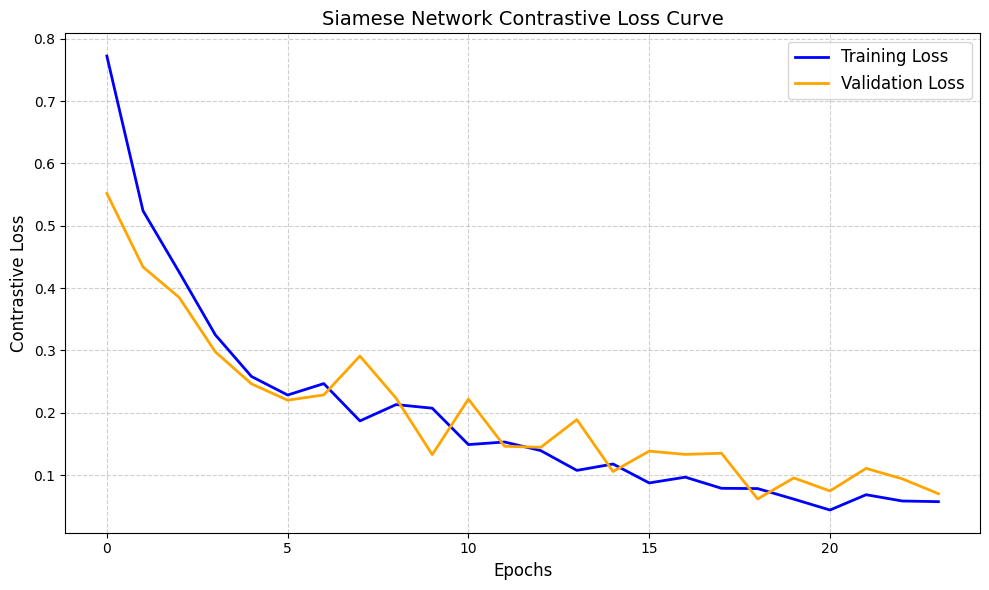

In [6]:
import matplotlib.pyplot as plt

# Plot the training and validation loss curves
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss', color='blue', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='orange', linewidth=2)
plt.title('Siamese Network Contrastive Loss Curve', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Contrastive Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()